In [1]:
from pathlib import Path

# Get the project root directory
PROJECT_ROOT = Path.cwd().parent

# Define dataset paths
WHITEBOARD_PATH = PROJECT_ROOT / "datasets" / "whiteboard"
HANDWRITING_PATH = PROJECT_ROOT / "datasets" / "handwriting"

print("Project Root:", PROJECT_ROOT)
print("Whiteboard Path:", WHITEBOARD_PATH)
print("Handwriting Path:", HANDWRITING_PATH)

# Check whether folders exist
print("\nWhiteboard exists:", WHITEBOARD_PATH.exists())
print("Handwriting exists:", HANDWRITING_PATH.exists())

Project Root: C:\Users\skand\OneDrive\Documents\Code\ML\Project\Boardmind-AI
Whiteboard Path: C:\Users\skand\OneDrive\Documents\Code\ML\Project\Boardmind-AI\datasets\whiteboard
Handwriting Path: C:\Users\skand\OneDrive\Documents\Code\ML\Project\Boardmind-AI\datasets\handwriting

Whiteboard exists: True
Handwriting exists: True


In [2]:
import cv2
import matplotlib.pyplot as plt

train_images = WHITEBOARD_PATH / "train" / "images"
train_labels = WHITEBOARD_PATH / "train" / "labels"

image_files = list(train_images.glob("*"))

print("Total training images:", len(image_files))

image_path = image_files[0]

label_path = train_labels / f"{image_path.stem}.txt"

print("\nImage:", image_path.name)
print("Annotation:", label_path.name)

if label_path.exists():
    print("\nYOLO Annotation:")
    print(label_path.read_text())
else:
    print("Annotation file not found!")

Total training images: 7093

Image: 0030b0b11d665ac8_jpg.rf.15e5803a5c7d7b9df9c45dfcaed7601b.jpg
Annotation: 0030b0b11d665ac8_jpg.rf.15e5803a5c7d7b9df9c45dfcaed7601b.txt

YOLO Annotation:
1 0 0.9591249984375001 0.9045918046875 0.9986744734374999 0.9329327812500001 0.041788259375 0.01721155 0.0151434921875 0 0.28635170625 0 0.9591249984375001
0 0.2620801108760928 0.24874034303214856 0.2251199683211164 0.0751604390337981
0 0.367041490441619 0.471772329242095 0.43787134059717553 0.06263902164110532
0 0.3910527908099361 0.520224201107992 0.4800588405971755 0.06386655251991762
0 0.3568859683979909 0.6953689536152744 0.3784963405971755 0.06091138558944351
0 0.8972117359375 0.5861204640625 0.1418078578125 0.5446574625 0.1445004125 0.5776133578125 0.8955984265625 0.6627878046875 0.8972117359375 0.5861204640625
0 0.7861462875 0.870262928125 0.18173721874999998 0.7954451312499999 0.1791879359375 0.8319015656250001 0.774105128125 0.9174023609375 0.7861462875 0.870262928125
0 0.492625121875 0.7801

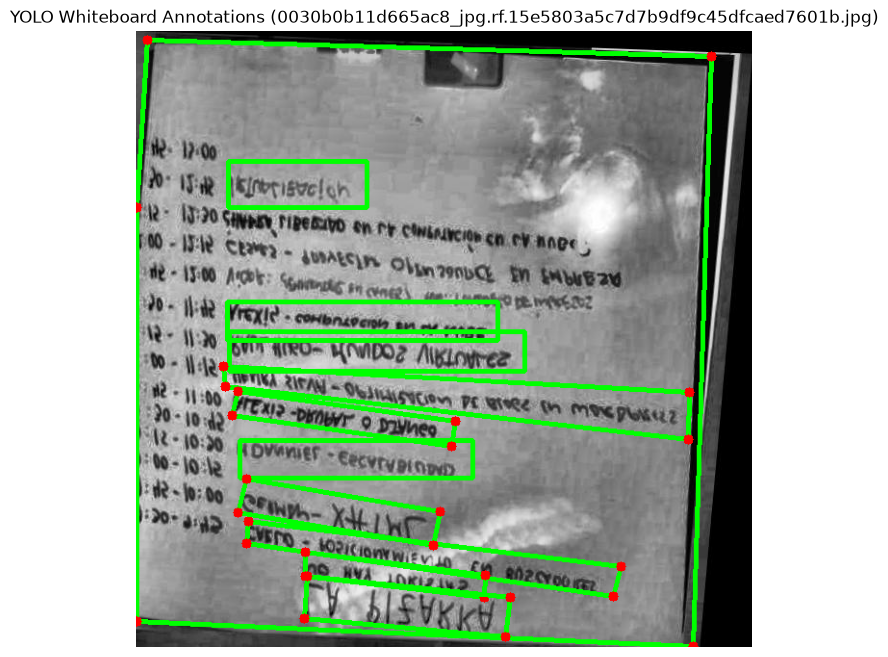

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Select image
image_path = image_files[0]
label_path = train_labels / f"{image_path.stem}.txt"

# Read image
image = cv2.imread(str(image_path))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

height, width = image.shape[:2]

# Read annotations (supports both bounding boxes and segmentation polygons)
if label_path.exists():
    annotations = label_path.read_text().strip().splitlines()

    for annotation in annotations:
        values = list(map(float, annotation.split()))
        class_id = int(values[0])

        if len(values) == 5:
            # Bounding box format: class cx cy w h
            cx, cy, w, h = values[1:]
            x1 = int((cx - w / 2) * width)
            y1 = int((cy - h / 2) * height)
            x2 = int((cx + w / 2) * width)
            y2 = int((cy + h / 2) * height)
            cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 3)
        elif len(values) >= 7 and (len(values) - 1) % 2 == 0:
            # Polygon format
            coordinates = np.array(values[1:]).reshape(-1, 2)
            coordinates[:, 0] *= width
            coordinates[:, 1] *= height
            polygon = coordinates.astype(np.int32)
            cv2.polylines(image, [polygon], isClosed=True, color=(0, 255, 0), thickness=3)
            for point in polygon:
                cv2.circle(image, tuple(point), 5, (255, 0, 0), -1)

    plt.figure(figsize=(12, 8))
    plt.imshow(image)
    plt.axis('off')
    plt.title(f'YOLO Whiteboard Annotations ({image_path.name})')
    plt.show()


In [4]:
print('IMAGE NAME:', image_path.name)
print('LABEL NAME:', label_path.name)
print('\nIMAGE DIMENSIONS:')
print('Width:', width)
print('Height:', height)

print('\nRAW YOLO ANNOTATION:')
if label_path.exists():
    print(label_path.read_text())
    print('\nPARSED ANNOTATIONS:')
    for line in label_path.read_text().strip().splitlines():
        values = list(map(float, line.split()))
        class_id = int(values[0])
        if len(values) == 5:
            print(f'Class {class_id} [Bounding Box] -> Center: ({values[1]:.4f}, {values[2]:.4f}), Size: ({values[3]:.4f}, {values[4]:.4f})')
        else:
            num_points = (len(values) - 1) // 2
            print(f'Class {class_id} [Polygon] -> {num_points} vertices')


IMAGE NAME: 0030b0b11d665ac8_jpg.rf.15e5803a5c7d7b9df9c45dfcaed7601b.jpg
LABEL NAME: 0030b0b11d665ac8_jpg.rf.15e5803a5c7d7b9df9c45dfcaed7601b.txt

IMAGE DIMENSIONS:
Width: 640
Height: 640

RAW YOLO ANNOTATION:
1 0 0.9591249984375001 0.9045918046875 0.9986744734374999 0.9329327812500001 0.041788259375 0.01721155 0.0151434921875 0 0.28635170625 0 0.9591249984375001
0 0.2620801108760928 0.24874034303214856 0.2251199683211164 0.0751604390337981
0 0.367041490441619 0.471772329242095 0.43787134059717553 0.06263902164110532
0 0.3910527908099361 0.520224201107992 0.4800588405971755 0.06386655251991762
0 0.3568859683979909 0.6953689536152744 0.3784963405971755 0.06091138558944351
0 0.8972117359375 0.5861204640625 0.1418078578125 0.5446574625 0.1445004125 0.5776133578125 0.8955984265625 0.6627878046875 0.8972117359375 0.5861204640625
0 0.7861462875 0.870262928125 0.18173721874999998 0.7954451312499999 0.1791879359375 0.8319015656250001 0.774105128125 0.9174023609375 0.7861462875 0.870262928125
0